<a href="https://colab.research.google.com/github/Muhammad-Mehdi-0/ML-Labs/blob/main/Lab8_SVM_Completed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name:**Muhammad Mehdi Mangi
- **Student ID:**023-24-0028
- **Section:**B
- **GitHub:**https://github.com/Muhammad-Mehdi-0/ML-Labs
- **Kaggle:**https://www.kaggle.com/muhammadmehdi01
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** <paste the Kaggle URL you used>

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [2]:
# Part 0 — load and clean the dataset (reuses the Lab 2 pipeline)
import os, time, warnings
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_recall_curve, average_precision_score)

# Upload clean_churn.csv from Lab 2 (or the original WA_Fn-UseC_-Telco-Customer-Churn.csv)
try:
    from google.colab import files
    files.upload()
except ImportError:
    pass

if os.path.exists("clean_churn.csv"):
    df = pd.read_csv("clean_churn.csv")
else:                                                    # fallback: redo the Lab 2 cleaning
    df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce").fillna(0)

print("Shape:", df.shape, "| missing values:", int(df.isnull().sum().sum()))
df["Churn"].value_counts()

Saving clean_churn.csv to clean_churn (1).csv
Shape: (7043, 21) | missing values: 0


,count
Churn,
No,5174
Yes,1869


In [3]:
# Part 0 — one-hot encode, define X and y, split (same split as Labs 3, 4 and 6)
y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["Churn", "customerID"])
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
X = pd.get_dummies(X, columns=cat_cols, drop_first=True).astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Churn rate  train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

def evaluate(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred)}

X_train: (5634, 30) | X_test: (1409, 30)
Churn rate  train: 0.265  test: 0.265


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [4]:
# Task 1.1 — unscaled linear SVM
# max_iter is capped so the unscaled run cannot run forever; a ConvergenceWarning means it hit the cap.
MAX_ITER = 500_000

def fit_timed(model, Xtr, ytr):
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        t0 = time.time(); model.fit(Xtr, ytr); secs = time.time() - t0
    return secs, sorted({x.category.__name__ for x in w})

svm_raw = SVC(kernel="linear", random_state=42, max_iter=MAX_ITER)
t_raw, warn_raw = fit_timed(svm_raw, X_train, y_train)
m_raw = evaluate(y_test, svm_raw.predict(X_test))
print(f"UNSCALED: fit time {t_raw:.1f}s | warnings: {warn_raw or 'none'}")
print(pd.Series(m_raw).round(4))

UNSCALED: fit time 18.8s | warnings: ['ConvergenceWarning']
Accuracy     0.5735
Precision    0.3408
Recall       0.6497
F1           0.4471
dtype: float64


In [5]:
# Task 1.1 — scaled linear SVM (scaler fit on TRAIN only)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

svm_sc = SVC(kernel="linear", random_state=42, max_iter=MAX_ITER)
t_sc, warn_sc = fit_timed(svm_sc, X_train_s, y_train)
m_sc = evaluate(y_test, svm_sc.predict(X_test_s))
print(f"SCALED: fit time {t_sc:.1f}s | warnings: {warn_sc or 'none'}")

scaling_cmp = pd.DataFrame({"Unscaled": m_raw, "Scaled": m_sc}).T
scaling_cmp["Fit time (s)"] = [t_raw, t_sc]
scaling_cmp["Warnings"] = [", ".join(warn_raw) or "none", ", ".join(warn_sc) or "none"]
scaling_cmp.round(4)

SCALED: fit time 1.8s | warnings: none


,Accuracy,Precision,Recall,F1,Fit time (s),Warnings
Unscaled,0.5735,0.3408,0.6497,0.4471,18.8272,ConvergenceWarning
Scaled,0.7885,0.6195,0.5267,0.5694,1.7540,none


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer:*
⚠ *Use the table printed above.* The scaled linear SVM reached accuracy [__] and F1 [__], versus [__] and [__] for the unscaled one. Training took [__] s on scaled data and [__] s on unscaled data, [and the unscaled run raised a ConvergenceWarning / hit the iteration cap, while the scaled run converged normally].

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer:*
An SVM finds the hyperplane that maximizes the margin, and the margin is a geometric distance computed from dot products between feature vectors. Features with a very large numeric range, such as `TotalCharges` (thousands) and `MonthlyCharges` (tens to hundreds), dominate those distances, while the 0/1 dummy columns and small-range features barely influence them. The optimizer therefore struggles: the problem is badly conditioned, the weights on small-scale features have to become very large to matter, and the solver converges slowly or not at all. After standardizing, every feature has mean 0 and variance 1, so each contributes comparably to the margin.

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer:*
I will use the **scaled** version (`StandardScaler` fitted on the training set only) for every later SVM, because it trains faster, converges reliably, and lets all features contribute fairly to the margin and kernel distances.

---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [6]:
# Task 2.1 — train linear / rbf / poly SVMs on the SCALED data and collect metrics
kernel_models, rows = {}, []
for kern in ["linear", "rbf", "poly"]:
    m = SVC(kernel=kern, random_state=42, max_iter=MAX_ITER)
    secs, _ = fit_timed(m, X_train_s, y_train)
    pred = m.predict(X_test_s)
    kernel_models[kern] = (m, pred)
    rows.append({"Kernel": kern, **evaluate(y_test, pred),
                 "Support vectors": int(m.support_.shape[0]), "Fit time (s)": round(secs, 1)})
print("done")

done


In [7]:
# Task 2.1 — comparison table
kernel_df = pd.DataFrame(rows).set_index("Kernel")
kernel_df.round(4)

,Accuracy,Precision,Recall,F1,Support vectors,Fit time (s)
Kernel,,,,,,
linear,0.7885,0.6195,0.5267,0.5694,2567,1.7
rbf,0.7928,0.6444,0.4893,0.5562,2657,1.2
poly,0.7892,0.6421,0.4652,0.5395,2736,1.1


Best kernel by F1: linear
[[TN, FP], [FN, TP]] = [[914, 121], [177, 197]]


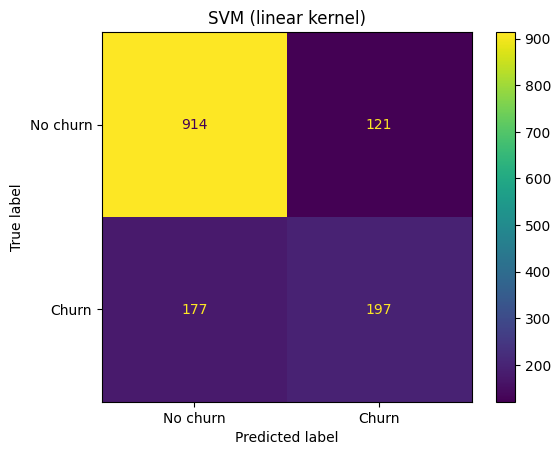

In [8]:
# Task 2.1 — confusion matrix for the best kernel (by F1)
best_kernel = kernel_df["F1"].idxmax()
print("Best kernel by F1:", best_kernel)
cm = confusion_matrix(y_test, kernel_models[best_kernel][1])
print("[[TN, FP], [FN, TP]] =", cm.tolist())
ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot()
plt.title(f"SVM ({best_kernel} kernel)"); plt.show()

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer:*
⚠ *Use your table.* The [kernel] kernel gave the best F1 ([__]), compared with [__] and [__] for the others. [This does / does not surprise me: the RBF kernel can model non-linear boundaries, but this dataset is largely well separated by a linear combination of features (tenure, contract type, charges), so a linear kernel can be just as good.]

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer:*
⚠ *Use the "Support vectors" column.* The [kernel] kernel used the most support vectors ([__] out of [__] training points). A large share of training points being support vectors means many points sit on or inside the margin, i.e. the classes overlap heavily and/or the boundary is complex and has to bend around many individual points, which also makes the model slower to predict and more prone to overfitting.

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer:*
⚠ *Pick from your table. The lab's Part 4 tunes an RBF kernel, so if you do not choose RBF, justify that clearly.* I carry forward the [RBF] kernel because its F1 ([__]) is [the highest / within __ of the best], and it has tunable C and gamma that can be improved with a grid search, whereas the linear kernel has only C to tune.

---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [9]:
# Task 3.1 — PCA to 2 components on the SCALED training features
pca = PCA(n_components=2, random_state=42)
Z_train = pca.fit_transform(X_train_s)
print("Explained variance ratio:", pca.explained_variance_ratio_.round(4))
print("Total explained variance:", round(pca.explained_variance_ratio_.sum(), 4))

# For speed, the 2-D models use a stratified sample of 2,000 training points
rng = np.random.RandomState(42)
idx = np.concatenate([rng.choice(np.where(y_train.values == c)[0],
                                 size=int(2000 * (y_train.values == c).mean()), replace=False)
                      for c in [0, 1]])
Z_s, y_s = Z_train[idx], y_train.values[idx]
print("2-D sample size:", len(idx))

Explained variance ratio: [0.3325 0.1198]
Total explained variance: 0.4522
2-D sample size: 1999


In [10]:
# Task 3.1 — train RBF SVMs at 3 different C values on the 2-D projection
C_values = [0.01, 1, 100]
models_2d = {}
for C in C_values:
    models_2d[C] = SVC(kernel="rbf", C=C, gamma="scale", random_state=42).fit(Z_s, y_s)
    print(f"C = {C:>6}: support vectors = {models_2d[C].support_.shape[0]}")

C =   0.01: support vectors = 1068
C =      1: support vectors = 995
C =    100: support vectors = 954


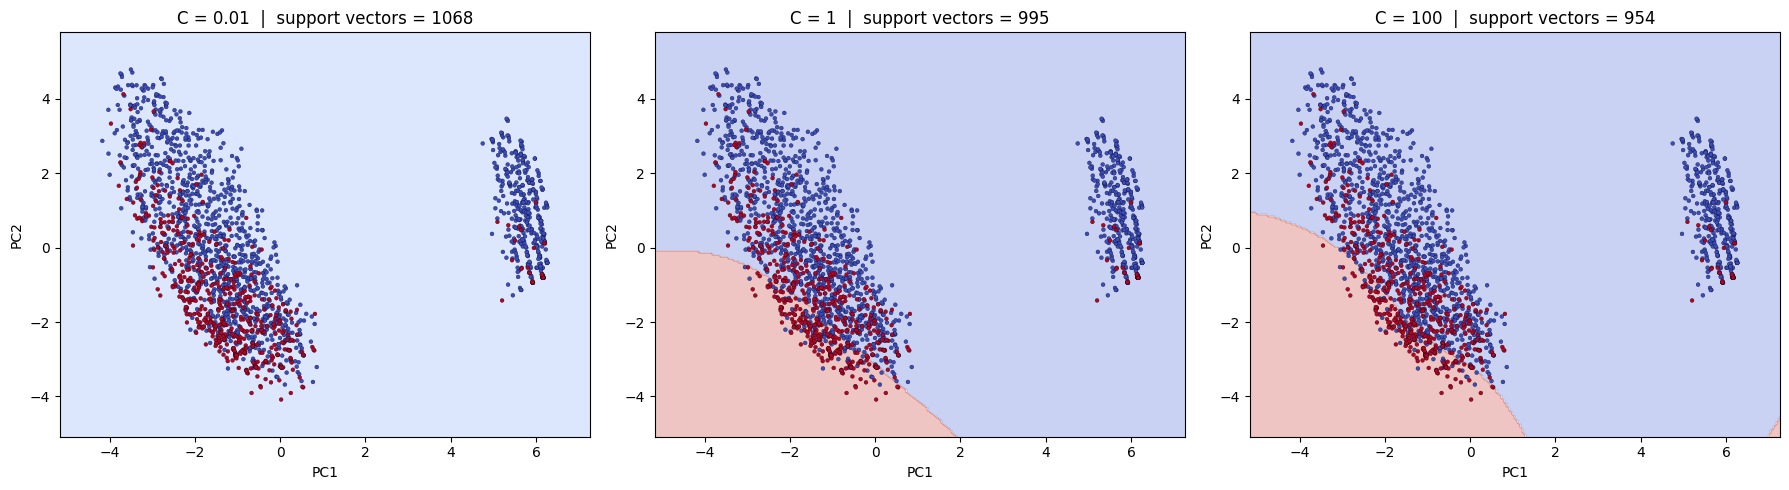

In [11]:
# Task 3.1 — decision boundary for each C (mesh grid + contourf)
x_min, x_max = Z_s[:, 0].min() - 1, Z_s[:, 0].max() + 1
y_min, y_max = Z_s[:, 1].min() - 1, Z_s[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, C in zip(axes, C_values):
    Zg = models_2d[C].predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, Zg, alpha=0.3, cmap="coolwarm")
    ax.scatter(Z_s[:, 0], Z_s[:, 1], c=y_s, cmap="coolwarm", s=8, edgecolor="k", linewidth=0.2)
    ax.set_title(f"C = {C}  |  support vectors = {models_2d[C].support_.shape[0]}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); plt.show()

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer:*
As C increases the boundary becomes more complex and wiggly: [describe what your three plots show, e.g. C = 0.01 gives a smooth, almost simple boundary that mostly predicts one class, while C = 100 produces small, twisty regions around individual points]. A larger C penalizes margin violations more heavily, so the model works harder to classify every training point correctly.

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer:*
⚠ *Use the counts printed above (C = 0.01 / 1 / 100).* The number of support vectors went from [__] to [__] to [__]. [Typically it decreases as C grows, because a high C tolerates fewer margin violations and so a narrower margin with fewer points inside it, which matches the theory that C controls the penalty for margin violations. If your counts do not follow this, say so and explain, e.g. heavily overlapping classes in 2-D keep many points inside the margin even at large C.]

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer:*
⚠ *Edit to match your plots.* C = 100 looks like it is overfitting: the boundary forms small, irregular pockets around individual points of the overlapping classes. C = 0.01 looks like it is underfitting: the boundary is too simple and [labels almost everything as the majority class (No churn)], ignoring real structure. C = 1 is the most reasonable compromise.

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer:*
The two principal components capture only [__]% of the variance (see the PCA output), so most of the information in the ~30 real features is thrown away. Points of different classes that overlap in the plot may be well separated in the full feature space, and the SVMs in the plot were trained on the 2-D projection, not the real model, so their boundaries are different from the real one. The plot also uses a sample of 2,000 training points. It is good for building intuition about C, but it should not be used to judge how well the real model separates the classes.

---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [ ]:
# Task 4.1 — define param_grid and run GridSearchCV (scaled TRAINING data, full feature set)
param_grid = {"C": [0.1, 1, 10, 100],
              "gamma": [0.001, 0.01, 0.1, 1]}
t0 = time.time()
gs = GridSearchCV(SVC(kernel="rbf", random_state=42), param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(X_train_s, y_train)
print(f"Grid search took {time.time() - t0:.0f}s")
print("Best params:", gs.best_params_)
print("Best CV F1:", round(gs.best_score_, 4))

In [ ]:
# Task 4.1 — heatmap of mean CV F1-score over the C x gamma grid
res = pd.DataFrame(gs.cv_results_)
heat = res.pivot(index="param_C", columns="param_gamma", values="mean_test_score").astype(float)
print(heat.round(3))

plt.figure(figsize=(6, 4.5))
plt.imshow(heat.values, cmap="viridis", aspect="auto")
plt.colorbar(label="Mean CV F1")
plt.xticks(range(len(heat.columns)), heat.columns); plt.yticks(range(len(heat.index)), heat.index)
plt.xlabel("gamma"); plt.ylabel("C"); plt.title("RBF SVM: CV F1 over C x gamma")
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        plt.text(j, i, f"{heat.values[i, j]:.2f}", ha="center", va="center", color="white", fontsize=9)
plt.show()

In [ ]:
# Task 4.1 — refit best estimator (GridSearchCV already refit it on all training data), evaluate on TEST
best_rbf = gs.best_estimator_
pred_tuned = best_rbf.predict(X_test_s)
tuned_metrics = evaluate(y_test, pred_tuned)
print(pd.Series(tuned_metrics).round(4))

cm = confusion_matrix(y_test, pred_tuned)
print("[[TN, FP], [FN, TP]] =", cm.tolist())
ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot()
plt.title("Tuned RBF SVM"); plt.show()

print("\nUn-tuned RBF (Part 2) F1:", round(kernel_df.loc["rbf", "F1"], 4),
      "| Tuned RBF F1:", round(tuned_metrics["F1"], 4),
      "| CV F1:", round(gs.best_score_, 4))

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer:*
⚠ The best combination was C = [__] and gamma = [__], with a mean 5-fold cross-validated F1 of [__].

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer:*
⚠ *Look at your heatmap.* [Several combinations around C = __ and gamma = __ score within about 0.01 of each other, so there is a broad plateau and the model is not very sensitive to the exact values / only one narrow corner scores well, so the model is sensitive to hyperparameters]. Very large gamma tends to overfit (each point only influences its immediate neighbourhood), and very small gamma and C tend to underfit.

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer:*
⚠ The CV F1 was [__] and the test F1 was [__], a gap of [__]. A small gap means the CV estimate is trustworthy and the model generalizes; a large gap would suggest overfitting to the training folds, an unlucky/unrepresentative test split, or leakage.

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer:*
⚠ The un-tuned RBF had F1 [__] and the tuned RBF has F1 [__] (a change of [__]). [Tuning improved / barely changed the result, so it was / was not worth the [__] seconds of computation.]

---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.


In [ ]:
# Task 5.1 — class_weight=None vs 'balanced' (using the best C and gamma from Part 4)
bestC, bestG = gs.best_params_["C"], gs.best_params_["gamma"]

# probability=True is needed for probability-like scores (it adds an internal 5-fold calibration, so it is slower)
svm_none = SVC(kernel="rbf", C=bestC, gamma=bestG, class_weight=None, probability=True, random_state=42).fit(X_train_s, y_train)
svm_bal = SVC(kernel="rbf", C=bestC, gamma=bestG, class_weight="balanced", probability=True, random_state=42).fit(X_train_s, y_train)

pred_none, pred_bal = svm_none.predict(X_test_s), svm_bal.predict(X_test_s)
cw_df = pd.DataFrame({"class_weight=None": evaluate(y_test, pred_none),
                      "class_weight='balanced'": evaluate(y_test, pred_bal)}).T
display(cw_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pr) in zip(axes, [("None", pred_none), ("balanced", pred_bal)]):
    cm = confusion_matrix(y_test, pr)
    print(f"{name}: [[TN, FP], [FN, TP]] =", cm.tolist())
    ConfusionMatrixDisplay(cm, display_labels=["No churn", "Churn"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"class_weight = {name}")
plt.tight_layout(); plt.show()

In [ ]:
# Task 5.1 — ROC and Precision-Recall curves for the balanced model
proba_bal = svm_bal.predict_proba(X_test_s)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba_bal)
prec, rec, _ = precision_recall_curve(y_test, proba_bal)
auc = roc_auc_score(y_test, proba_bal); ap = average_precision_score(y_test, proba_bal)

# operating point of the model's default predict() decision
tn, fp, fn, tp = confusion_matrix(y_test, pred_bal).ravel()
op_fpr, op_tpr = fp / (fp + tn), tp / (tp + fn)
op_prec, op_rec = tp / (tp + fp), tp / (tp + fn)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(fpr, tpr, label=f"ROC (AUC = {auc:.3f})"); ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[0].scatter([op_fpr], [op_tpr], color="red", s=80, zorder=5, label="default predict() threshold")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate (recall)")
ax[0].set_title("ROC curve (balanced SVM)"); ax[0].legend()

ax[1].plot(rec, prec, label=f"PR curve (AP = {ap:.3f})")
ax[1].scatter([op_rec], [op_prec], color="red", s=80, zorder=5, label="default predict() threshold")
ax[1].axhline(y_test.mean(), color="k", linestyle="--", alpha=0.4, label="churn base rate")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall curve (balanced SVM)"); ax[1].legend()
plt.tight_layout(); plt.show()
print("ROC AUC:", round(auc, 4), "| Average precision:", round(ap, 4))

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer:*
⚠ *Use the table printed above.* With `class_weight=None`, precision was [__] and recall [__]. With `'balanced'`, precision [rose / fell] to [__] and recall [rose / fell] to [__] (F1 went from [__] to [__]). [Typically recall rises noticeably and precision falls, because errors on the minority class (churners) are penalized more heavily.]

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer:*
Missing an actual churner is usually more costly: the company loses that customer's future revenue and never gets a chance to react, whereas wrongly flagging a loyal customer only costs a retention offer or a phone call. So recall on churners matters most, and I would deploy the **balanced** model, as long as its precision stays high enough that the retention team is not overwhelmed with false alarms. ⚠ *Support this with your own numbers, e.g. "it catches [__] of [__] churners versus [__] for the default model."*

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer:*
I had to set `probability=True` when creating the `SVC`. This makes scikit-learn fit an extra calibration step (Platt scaling, using internal 5-fold cross-validation) that maps the SVM's decision values to probabilities, which is why training becomes noticeably slower. The alternative is to use `decision_function()` scores directly.

⚠ *Also write 2–3 sentences interpreting the ROC and Precision-Recall plots: what the AUC / average precision tell you, and where the red default-threshold point sits on the curve (could moving the threshold give a better recall/precision balance?).*

---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [ ]:
# Task 6.1 — cross-model comparison table (same split as this lab, so the comparison is fair)
best_depth = 5     # <-- CHANGE to your Lab 3 chosen max_depth
chosen_k = 11      # <-- CHANGE to your Lab 6 chosen K
# <-- CHANGE the forest settings below to your Lab 4 best (tuned) Random Forest
rf_kwargs = dict(n_estimators=200, max_depth=None, min_samples_split=2, random_state=42)
final_svm = svm_bal     # <-- svm_bal (balanced) or svm_none: the SVM you consider your best (Part 5)

def timed_fit(model, Xtr, ytr):
    t0 = time.time(); model.fit(Xtr, ytr); return time.time() - t0

results, times = {}, {}
dt = DecisionTreeClassifier(max_depth=best_depth, random_state=42)
times["Decision Tree"] = timed_fit(dt, X_train, y_train)
results["Decision Tree"] = evaluate(y_test, dt.predict(X_test))

rf = RandomForestClassifier(**rf_kwargs)
times["Random Forest"] = timed_fit(rf, X_train, y_train)
results["Random Forest"] = evaluate(y_test, rf.predict(X_test))

lr = LogisticRegression(max_iter=1000, random_state=42)
times["Logistic Regression"] = timed_fit(lr, X_train_s, y_train)
results["Logistic Regression"] = evaluate(y_test, lr.predict(X_test_s))

knn = KNeighborsClassifier(n_neighbors=chosen_k)
times["KNN"] = timed_fit(knn, X_train_s, y_train)
results["KNN"] = evaluate(y_test, knn.predict(X_test_s))

svm_time = timed_fit(SVC(kernel="rbf", C=bestC, gamma=bestG,
                         class_weight=final_svm.class_weight, random_state=42), X_train_s, y_train)
times["SVM (RBF, tuned)"] = svm_time
results["SVM (RBF, tuned)"] = evaluate(y_test, final_svm.predict(X_test_s))

showdown = pd.DataFrame(results).T
showdown["Fit time (s)"] = pd.Series(times)
showdown.round(4)

In [ ]:
# Task 6.1 — bar chart of F1-score across all five models
f1s = showdown["F1"].sort_values()
plt.figure(figsize=(8, 4.5))
bars = plt.barh(f1s.index, f1s.values, color="steelblue")
for b, v in zip(bars, f1s.values):
    plt.text(v + 0.003, b.get_y() + b.get_height() / 2, f"{v:.3f}", va="center")
plt.xlabel("Test F1-score"); plt.title("F1-score by model (same train/test split)")
plt.xlim(0, max(0.9, f1s.max() + 0.1)); plt.tight_layout(); plt.show()

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer:*
⚠ *Use the table.* [Model] wins on F1-score ([__]) and [model] wins on recall ([__]). [They are / are not the same model.]

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer:*
⚠ *Use the "Fit time" column.* The SVM trained in [__] s compared with [__] s for the Decision Tree and [__] s for the Random Forest, and its F1 was [__] versus [__] / [__]. [The extra cost was / was not worth it because the gain was only __ F1 points.]

(c) Which single model would you recommend deploying, and why? (reference at least two metrics)

*Your answer:*
⚠ I recommend [model] because it has the best [F1 ([__]) and recall ([__])] while keeping precision at [__]. Since catching churners matters more than avoiding a few false alarms, I weigh recall and F1 more heavily than accuracy, which is misleading with only about 26% churners.

---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [ ]:
# Task 7.1 — generate and save svm_predictions.csv
final_model = final_svm        # change if you want a different SVM variant
proba = final_model.predict_proba(X_test_s)[:, 1]
pred = final_model.predict(X_test_s)

svm_predictions = pd.DataFrame({
    "customerID": df.loc[X_test.index, "customerID"].values,
    "true_label": y_test.values,
    "predicted_label": pred,
    "churn_probability": proba.round(4),
})
svm_predictions.to_csv("svm_predictions.csv", index=False)
print(svm_predictions.shape)
display(svm_predictions.head())

try:
    from google.colab import files
    files.download("svm_predictions.csv")
except ImportError:
    pass

**Executive Summary**

⚠ *Write 5–8 sentences using your own numbers. Template:*

I chose the [model] as the final model for predicting customer churn. On the held-out test set it reached an F1-score of [__], recall of [__], precision of [__] and accuracy of [__]. The main trade-off I made was using `class_weight='balanced'`, which [raised recall from __ to __ at the cost of precision dropping from __ to __], because missing a churner is more costly than sending an unnecessary retention offer. Feature scaling was essential for the SVM, and the tuned RBF kernel [improved / barely changed] F1 over the default. Compared with the Decision Tree, Random Forest, Logistic Regression and KNN, [the SVM was / was not] clearly better, and it was slower to train. One limitation of this analysis is [a single train/test split, no feature engineering, the 2-D plot is only an approximation, or the default 0.5 threshold was not tuned].

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer:*
⚠ *e.g. "[the unscaled SVM took __ s / failed to converge]", or "[the linear kernel matched the RBF kernel]", or "[tuning changed F1 by only __]".*

(b) If you had one more hour, what would you try next?

*Your answer:*
I would [engineer features such as tenure bands, try SMOTE or tune the decision threshold directly, compare against gradient boosting, and use a better projection (e.g. t-SNE or PCA on selected features) for visualization].